# 02 · Automatic labelling with TF-IDF similarity

**Goal:** give every candidate a label automatically, with no hand labelling, so the method scales to datasets far too large to label by hand.

**Approach (the usual workflow for this kind of task):**
1. Score each candidate with a **simple similarity method**: TF-IDF + cosine similarity to the keywords.
2. Turn the score into **automatic labels**: fit, not a fit, or unsure.
3. *(Later)* Train a model on these labels, so that fit becomes a probability.
4. *(Later)* A domain expert checks the top of the ranking and corrects it by starring candidates.

We also settle the duplicates question **with numbers** before removing anything.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from talent_ranker.config import FIGURES_DIR, FIT_MIN_SCORE, KEYWORDS
from talent_ranker.data import deduplicate, load_candidates
from talent_ranker.labelling import auto_label
from talent_ranker.similarity import tfidf_similarity

pd.set_option("display.max_colwidth", 90)
candidates = load_candidates()
profiles = deduplicate(candidates)
print(f"{len(candidates)} rows, {len(profiles)} distinct profiles")

104 rows, 53 distinct profiles


## 1. Are the duplicate rows really the same people?
Two different people *could* share a title, a city and a connection count. Before merging anything, we look at where the repeated rows sit in the file.

In [2]:
repeated = profiles[profiles["ids"].map(len) > 1]
repeated_ids = sorted(i for ids in repeated["ids"] for i in ids)
print(f"{len(repeated)} profiles appear more than once, using {len(repeated_ids)} rows")
no_gaps = repeated_ids == list(range(1, 66))
print(f"Those rows are ids {min(repeated_ids)} to {max(repeated_ids)}; no gaps: {no_gaps}")
first_id = {i: ids[0] for ids in profiles["ids"] for i in ids}
print("Each id -> id of its first copy:", {i: first_id[i] for i in range(14, 34)})

14 profiles appear more than once, using 65 rows
Those rows are ids 1 to 65; no gaps: True
Each id -> id of its first copy: {14: 1, 15: 1, 16: 2, 17: 3, 18: 4, 19: 1, 20: 2, 21: 3, 22: 4, 23: 5, 24: 6, 25: 7, 26: 8, 27: 27, 28: 28, 29: 27, 30: 28, 31: 1, 32: 2, 33: 3}


**Finding: the duplicates come from how the data was collected; they are not different people.**
- Every repeated row is in ids **1–65**, with no gaps. Those 65 rows hold only **14 profiles**. Ids 66–104 are 39 profiles that never repeat.
- The repeats follow a **cycle**: 14→1, 16→2, 17→3, 18→4 … then 31→1, 32→2, 33→3 … The same first batch of search results was collected again and again.
- Several groups share an exact, uncapped connection count, such as 85, 61 or 44. Different people matching on title, location *and* that number would be a big coincidence.

## 2. The similarity score: TF-IDF + cosine similarity

Each title and each keyword becomes a vector of word weights:
- **TF** (term frequency): how often a word appears in the title.
- **IDF** (inverse document frequency): rarer words across all titles get more weight. "aspiring" counts more than "human", which is in most titles.

**Cosine similarity** compares the direction of two vectors, so a title's length doesn't matter. The score runs from 0 (no shared words) to 1. With two keywords, a title keeps its **best** match, because the keywords are alternatives.

| Option | Verdict | Reason |
|---|---|---|
| **TF-IDF + cosine** | ✅ chosen | Simple, explainable, no training or downloads, weights informative words, gives a fine-grained score, and handles millions of titles quickly |
| Keyword coverage | ❌ | Only 4 possible scores: big ties, and every word weighs the same |
| Jaccard similarity | ❌ | Every word weighs the same, and long titles are punished |
| BM25 | ❌ | Built for long documents; on short titles it adds complexity for no benefit |
| Word vectors, SBERT | ⏭ Step 3 | Understand meaning but are more complex, so they come only once TF-IDF's limits are measured |

### 2a. First, with all 104 rows (duplicates kept)

In [3]:
candidates["similarity"] = tfidf_similarity(candidates["job_title"], KEYWORDS)
top_rows = candidates.sort_values("similarity", ascending=False, kind="stable")


def people_in(df):
    """Count different people (same title, location and connections = same person)."""
    return len(df.drop_duplicates(["job_title", "location", "connections"]))


print(f"Different people in the top 10 rows: {people_in(top_rows.head(10))}")
print(f"Different people in the top 20 rows: {people_in(top_rows.head(20))}")
top_rows[["id", "job_title", "similarity"]].head(10)

Different people in the top 10 rows: 3
Different people in the top 20 rows: 7


,id,job_title,similarity
2,3,Aspiring Human Resources Professional,0.743208
16,17,Aspiring Human Resources Professional,0.743208
20,21,Aspiring Human Resources Professional,0.743208
32,33,Aspiring Human Resources Professional,0.743208
45,46,Aspiring Human Resources Professional,0.743208
57,58,Aspiring Human Resources Professional,0.743208
96,97,Aspiring Human Resources Professional,0.743208
5,6,Aspiring Human Resources Specialist,0.684278
23,24,Aspiring Human Resources Specialist,0.684278
35,36,Aspiring Human Resources Specialist,0.684278


**Finding: duplicates wreck the ranking.** With all 104 rows, the **top 10 contains only 3 different people**, and the top 20 only 7. A recruiter would read the same "Aspiring Human Resources Professional" 7 times in a row.

They also change the word weights. IDF counts how many titles contain each word, so a title repeated 7 times counts 7 times. The same title scores 0.743 here but 0.756 on distinct profiles.

**Decision (proven with numbers): score and rank the 53 distinct profiles.** Nothing is lost, because each profile keeps its list of original ids, so all 104 rows still get a score in the final output.

### 2b. On the 53 distinct profiles

In [4]:
profiles["similarity"] = tfidf_similarity(profiles["job_title"], KEYWORDS)
ranked = profiles.sort_values("similarity", ascending=False, kind="stable")
print(f"Distinct similarity values: {profiles['similarity'].round(4).nunique()}")
ranked[["job_title", "similarity"]].head(20).round(3)

Distinct similarity values: 32


,job_title,similarity
2,Aspiring Human Resources Professional,0.756
45,Aspiring Human Resources Professional,0.756
5,Aspiring Human Resources Specialist,0.676
13,Seeking Human Resources Opportunities,0.674
47,Seeking Human Resources Position,0.674
21,"Aspiring Human Resources Manager, seeking internship in Human Resources.",0.628
12,Aspiring Human Resources Management student seeking an internship,0.461
20,Business Management Major and Aspiring Human Resources Manager,0.432
8,Seeking Human Resources HRIS and Generalist Positions,0.432
14,Experienced Retail Manager and aspiring Human Resources Professional,0.404


**Finding:** the ranking looks sensible at the top: short "Aspiring/Seeking Human Resources …" titles score 0.63–0.76. With **32 different values**, there are almost no ties.

**A weakness shows already.** Long titles score lower even when they are clearly a fit. Their keyword words are diluted by many other words:
- "2019 C.T. Bauer College of Business Graduate … aspiring Human Resources professional" scores 0.25;
- "Human Resources Professional", a working professional rather than an aspiring one, scores 0.39.

This is a known limit of word-count methods.

## 3. Do the settings help? (each one tested, not assumed)
We compare plain TF-IDF with each setting added in turn, on titles that show the difference.

In [5]:
examples = [
    "Aspiring Human Resources Professional",
    "HR Senior Specialist",
    "HR Manager at Endemol Shine North America",
    "2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human ",
    "Resources professional",
    "Experienced Retail Manager and aspiring Human Resources Professional"
]
titles = profiles["job_title"]
settings = pd.DataFrame(
    {
        "plain TF-IDF": tfidf_similarity(
            titles, KEYWORDS, stop_words=None, expand_abbreviations=False
        ),
        "+ stop words removed": tfidf_similarity(titles, KEYWORDS, expand_abbreviations=False),
        "+ HR spelled out (chosen)": tfidf_similarity(titles, KEYWORDS),
    }
).set_index(titles)
settings[~settings.index.duplicated()].loc[examples].round(3)

,plain TF-IDF,+ stop words removed,+ HR spelled out (chosen)
job_title,,,
Aspiring Human Resources Professional,0.762,0.762,0.756
HR Senior Specialist,0.000,0.000,0.239
HR Manager at Endemol Shine North America,0.000,0.000,0.148
2019 C.T. Bauer College of Business Graduate (Magna Cum Laude) and aspiring Human Resources professional,0.242,0.255,0.251
Experienced Retail Manager and aspiring Human Resources Professional,0.391,0.410,0.404


**Finding: both settings help, and each fixes a specific problem.**

| Title | Plain | + stop words removed | + HR spelled out |
|---|---|---|---|
| HR Senior Specialist | 0 | 0 | **0.239** |
| HR Manager at Endemol Shine | 0 | 0 | **0.148** |
| C.T. Bauer graduate … aspiring HR professional | 0.242 | **0.255** | 0.251 |
| Experienced Retail Manager and aspiring HR Professional | 0.391 | **0.410** | 0.404 |

- **Stop words** ("at", "and", "of") carry no meaning. Removing them stops them diluting long titles.
- **"HR" → "human resources":** TF-IDF only matches identical words. Without this rule, HR titles score the same as an English teacher.
- **Two-word phrases (bigrams)** were also rejected: they push long titles down further.

## 4. From score to automatic labels
We split the score into three zones:

| Zone | Rule | Why |
|---|---|---|
| **1 = fit** | similarity ≥ 0.3 | Above 0.3 every title contains "human resources" plus "aspiring" or "seeking", with one exception |
| **0 = not a fit** | similarity = 0 | The title shares no word with either keyword, the only case we can be sure of without a person |
| **unsure (no label)** | in between | TF-IDF can't tell. Forcing a label would teach the model mistakes, so the model scores these instead (later) |

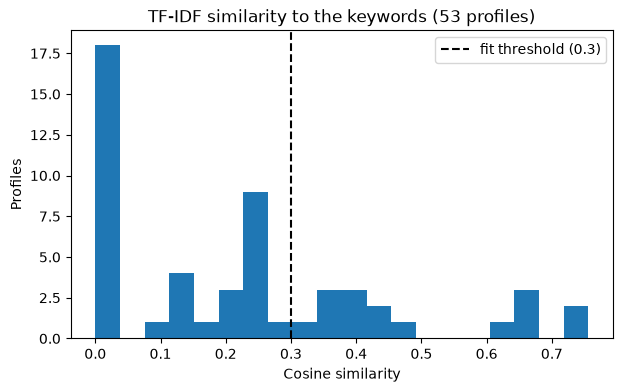

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(profiles["similarity"], bins=20)
ax.axvline(FIT_MIN_SCORE, color="black", linestyle="--", label=f"fit threshold ({FIT_MIN_SCORE})")
ax.set(
    title="TF-IDF similarity to the keywords (53 profiles)",
    xlabel="Cosine similarity",
    ylabel="Profiles",
)
ax.legend()
fig.savefig(FIGURES_DIR / "tfidf_similarity.png", dpi=150, bbox_inches="tight")

**Why 0.3:** the scores have no clean gap, but 0.3 sits in a sparse area between a cluster at 0.2–0.27 (titles where "human resources" appears among many other words) and the aspiring/seeking group above. The bar at 0 holds 18 profiles that share no word with the keywords. The threshold is a choice, kept in `config.py`; Steps 4 and 6 test how sensitive the results are to it.

In [7]:
profiles["auto_label"] = auto_label(profiles["similarity"])
zone = profiles["auto_label"].map({1: "1 = fit", 0: "0 = not a fit"}).fillna("unsure")
zone.value_counts()

auto_label
unsure           19
0 = not a fit    18
1 = fit          16
Name: count, dtype: int64

In [8]:
for name in ["1 = fit", "unsure", "0 = not a fit"]:
    group = profiles[zone == name].sort_values("similarity", ascending=False)
    print(f"\n=== {name} ({len(group)} profiles)")
    for title, score in zip(group["job_title"], group["similarity"], strict=True):
        print(f"{score:.2f}  {title}")


=== 1 = fit (16 profiles)
0.76  Aspiring Human Resources Professional
0.76  Aspiring Human Resources Professional
0.68  Aspiring Human Resources Specialist
0.67  Seeking Human Resources Opportunities
0.67  Seeking Human Resources Position
0.63  Aspiring Human Resources Manager, seeking internship in Human Resources.
0.46  Aspiring Human Resources Management student seeking an internship
0.43  Business Management Major and Aspiring Human Resources Manager
0.43  Seeking Human Resources HRIS and Generalist Positions
0.40  Experienced Retail Manager and aspiring Human Resources Professional
0.39  Human Resources Professional
0.39  Student at Humber College and Aspiring Human Resources Generalist
0.37  Seeking Human Resources Opportunities. Open to travel and relocation.
0.36  Aspiring Human Resources Manager Graduating May 2020 Seeking an Entry-Level Human Resources Position in St. Louis
0.35  Liberal Arts Major. Aspiring Human Resources Analyst.
0.33  Aspiring Human Resources Professiona

**Result: 16 fit, 19 unsure, 18 not a fit, with no hand labelling.**

Reading the three groups:
- **Fit (16):** all clearly aspiring or seeking HR, except "Human Resources Professional", which is someone already working in HR. That's one noisy label out of 16.
- **Unsure (19):** this is where TF-IDF struggles, which is exactly why these got no label.
  - Some are long but clearly aspiring titles: the C.T. Bauer graduate, "Retired Army … seeking a position in Human Resources", "Aspiring … Passionate about …", and the HR Management Major.
  - Others are working HR professionals: Generalists, Specialists, Directors.
  - One is the **Nortia Staffing job ad**, which isn't a person at all and will need a filter (later).
- **Not a fit (18):** no keyword word at all. Most are clearly not HR. Two are HR roles in other words ("People Development Coordinator", "SVP, CHRO"), but neither is an *aspiring* candidate, so the label still holds for this search.

**Known limits, stated openly:** the labels inherit TF-IDF's blind spots (long titles, synonyms, context). The model in next steps should rank the *unsure* group better than TF-IDF alone. A domain expert's check of the top rows is what finally tells us how good the ranking is.

## Summary

| Question | Answer |
|---|---|
| Are duplicates the same people? | **Yes.** All 65 repeated rows sit in ids 1–65 in a repeating collection cycle |
| Should we merge them? | **Yes, proven:** with duplicates the top 10 holds only **3 different people**, and the word weights shift. All 104 ids still get a score |
| Similarity method | TF-IDF + cosine, stop words removed, "HR" spelled out (each setting tested) |
| Automatic labels | **16 fit, 18 not a fit, 19 unsure**, with no hand labelling, so it scales to any dataset size |
| Where TF-IDF is weak | Long titles are diluted, synonyms aren't understood, and context isn't seen (the job ad) |

**Next:** pretrained **word vectors** (GloVe / fastText), which know that words with similar meanings are related ("people development" ≈ HR). We compare them with TF-IDF and keep whichever represents titles better.